In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import sklearn, pandas as pd
from sklearn.datasets import load_diabetes
X, y = load_diabetes(return_X_y=True, as_frame=True)
print(X.shape, y.shape)

(442, 10) (442,)


In [3]:
df_x = pd.DataFrame(X)
df_y = pd.DataFrame(y)

# Phase-1 EDA

In [4]:
df_x.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [5]:
df_y.head()

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0


In [6]:
df_x.info()
df_y.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   target  442 non-null    float64
dtypes: float64(1)
memory usage: 3.6 KB


In [7]:
df_x.isnull().sum()

age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

In [8]:
df_y.isnull().sum()

target    0
dtype: int64

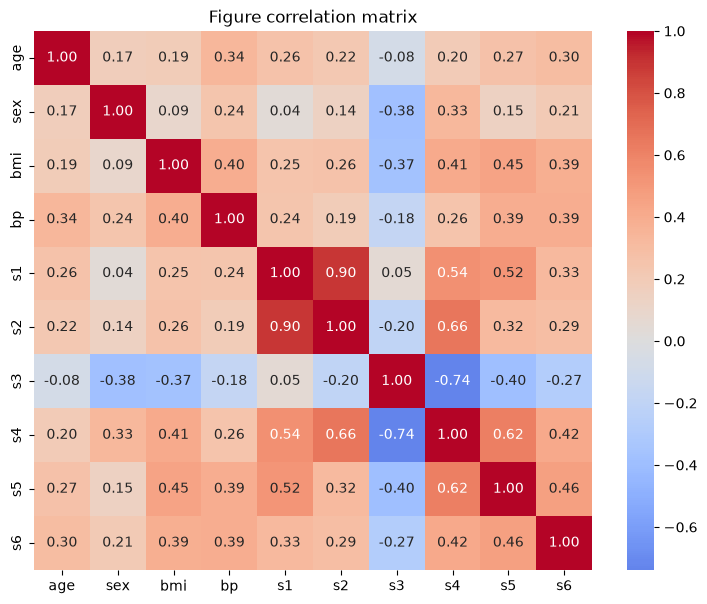

In [9]:
corr = df_x.corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f",center=0)
plt.title("Figure correlation matrix")
plt.savefig("D:\\Research Project\\results\\figures\\corr_matrix.png",dpi=150,bbox_inches='tight')
plt.show()

In [10]:
pd.concat([X, y], axis=1).corr()["target"].sort_values()

s3       -0.394789
sex       0.043062
s2        0.174054
age       0.187889
s1        0.212022
s6        0.382483
s4        0.430453
bp        0.441482
s5        0.565883
bmi       0.586450
target    1.000000
Name: target, dtype: float64

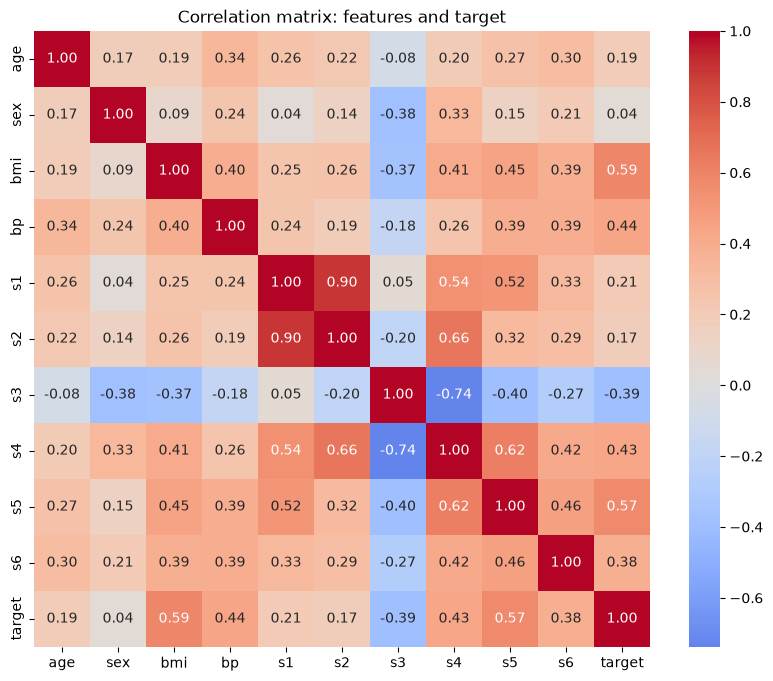

In [11]:
df = df_x.copy()
df["target"] = df_y

corr_full = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_full, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix: features and target")
plt.savefig("D:\\Research Project\\results\\figures\\target_corr_matrix.png",dpi=150,bbox_inches='tight')
plt.show()

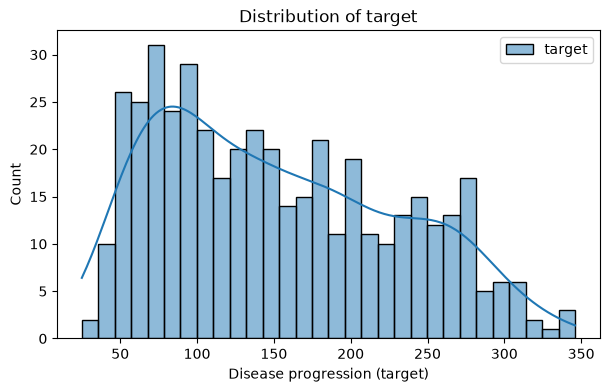

In [12]:
plt.figure(figsize=(7, 4))
sns.histplot(df_y, bins=30, kde=True)
plt.xlabel("Disease progression (target)")
plt.title("Distribution of target")
plt.savefig("../results/figures/target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Obeservations:
1 The target runs from 25 to 346. It is right skewed, with a long tail to the right. The mean is 152.1, and the median is 140. The distribution is not normal, which may affect the performance of some models.
2 bmi, s5, bp, and s4 has the highest correlation with the target, while sex has the lowest correlation. This suggests that bmi, s5, bp, and s4 may be more important features for predicting disease progression.
3 Multicollinearity is present in s1 and s2 as well as in s3 and s4, which may affect the performance of some models. Multicollinearity is present so regularization may stablize the coefficients.

# Phase-2

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df_x, df_y['target'], test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(353, 10) (89, 10)


In [14]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 37.9 ,-241.96, 542.43,..., 275.32, 736.2 , 48.67]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,151.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [15]:
y_pred = lr.predict(X_test)

In [16]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")    

MSE:  2900.19
RMSE: 53.85
R²:   0.4526


In [17]:
coef_table = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lr.coef_
})
coef_table.loc[len(coef_table)] = ["intercept", lr.intercept_]

coef_table.to_csv("D:\\Research Project\\results\\tables\\baseline_coefficients.csv", index=False)
coef_table

,feature,coefficient
0,age,37.904021
1,sex,-241.964362
2,bmi,542.428759
3,bp,347.703844
4,s1,-931.488846
5,s2,518.062277
6,s3,163.419983
7,s4,275.317902
8,s5,736.198859
9,s6,48.670657


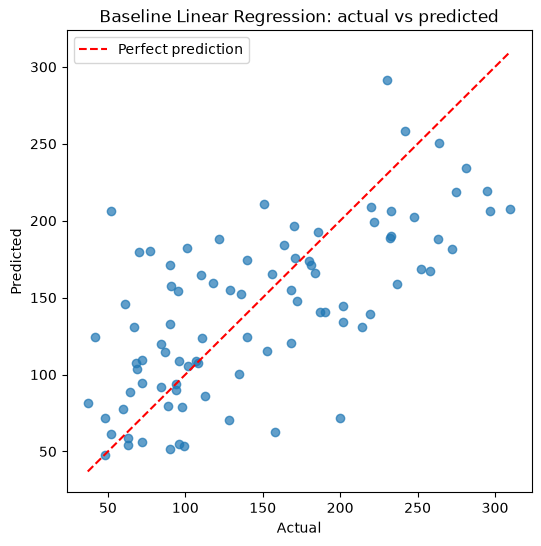

In [18]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Baseline Linear Regression: actual vs predicted")
plt.legend()
plt.savefig("D:\\Research Project\\results\\figures\\baseline_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

# Using K-Fold Cross Validation (k=5)

In [19]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    LinearRegression(), X_train, y_train,
    cv=kf, scoring="neg_root_mean_squared_error"
)
cv_rmse = -cv_scores

cv_rmse_mean = cv_rmse.mean()
cv_rmse_std = cv_rmse.std()

print("Fold RMSEs:", np.round(cv_rmse, 2))
print(f"CV RMSE mean: {cv_rmse_mean:.2f}")
print(f"CV RMSE std:  {cv_rmse_std:.2f}")

Fold RMSEs: [53.37 56.76 53.04 54.46 59.34]
CV RMSE mean: 55.39
CV RMSE std:  2.36


In [20]:
results = pd.DataFrame([{
    "model": "LinearRegression",
    "alpha": None,
    "test_MSE": mse,
    "test_RMSE": rmse,
    "test_R2": r2,
    "cv_RMSE_mean": cv_rmse_mean,
    "cv_RMSE_std": cv_rmse_std,
}])

results.to_csv("D:/Research Project/results/tables/results_table.csv", index=False)
results

,model,alpha,test_MSE,test_RMSE,test_R2,cv_RMSE_mean,cv_RMSE_std
0,LinearRegression,None,2900.193628,53.853446,0.452603,55.394633,2.361496


The CV RMSE (55.39 ± 2.36) is consistent with the test RMSE (53.85), indicating that the baseline performance is stable across different data splits.

In [21]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
rows = []
coef_records = []   # for step 27

for name, Model in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for a in alphas:
        if name == "Lasso":
            model = Model(alpha=a, max_iter=100000)
        else:
            model = Model(alpha=a)

        # Same kf as the baseline (steps 21 and 22)
        cv_scores = cross_val_score(
            model, X_train, y_train,
            cv=kf, scoring="neg_root_mean_squared_error"
        )
        cv_rmse = -cv_scores

        # Fit on the full training set, evaluate on the same test set
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        test_rmse = np.sqrt(mean_squared_error(y_test, pred))
        test_r2 = r2_score(y_test, pred)

        rows.append({
            "model": name,
            "alpha": a,
            "cv_RMSE_mean": cv_rmse.mean(),
            "cv_RMSE_std": cv_rmse.std(),
            "test_RMSE": test_rmse,
            "test_R2": test_r2,
            "n_zero_coefs": int((model.coef_ == 0).sum()),
        })
        coef_records.append({"model": name, "alpha": a,
                             **dict(zip(X_train.columns, model.coef_))})

reg_results = pd.DataFrame(rows)
reg_results.to_csv("D:/Research Project/results/tables/regularized_results.csv", index=False)
reg_results.round(3)

,model,alpha,cv_RMSE_mean,cv_RMSE_std,test_RMSE,test_R2,n_zero_coefs
0,Ridge,0.001,55.378,2.371,53.813,0.453,0
1,Ridge,0.010,55.409,2.365,53.687,0.456,0
2,Ridge,0.100,55.527,2.478,53.446,0.461,0
3,Ridge,1.000,60.021,4.351,55.474,0.419,0
4,Ridge,10.000,72.611,5.555,66.663,0.161,0
5,Ridge,100.000,77.439,5.634,72.344,0.012,0
6,Ridge,1000.000,78.062,5.638,73.132,-0.009,0
7,Lasso,0.001,55.381,2.368,53.818,0.453,0
8,Lasso,0.010,55.363,2.325,53.652,0.457,0
9,Lasso,0.100,55.541,2.389,52.898,0.472,3


In [22]:
baseline_row = {"model": "LinearRegression", "alpha": np.nan,
                "cv_RMSE_mean": cv_rmse_mean, "cv_RMSE_std": cv_rmse_std,
                "test_RMSE": rmse, "test_R2": r2, "n_zero_coefs": 0}
all_results = pd.concat([pd.DataFrame([baseline_row]), reg_results], ignore_index=True)
all_results.to_csv("D:/Research Project/results/tables/all_results.csv", index=False)

In [23]:
all_results

,model,alpha,cv_RMSE_mean,cv_RMSE_std,test_RMSE,test_R2,n_zero_coefs
0,LinearRegression,NaN,55.394633,2.361496,53.853446,0.452603,0
1,Ridge,0.001,55.378371,2.370614,53.812835,0.453428,0
2,Ridge,0.010,55.409425,2.364588,53.686965,0.455982,0
3,Ridge,0.100,55.526782,2.478464,53.446112,0.460852,0
4,Ridge,1.000,60.021402,4.350535,55.474462,0.419153,0
5,Ridge,10.000,72.611402,5.554996,66.662978,0.161226,0
6,Ridge,100.000,77.439271,5.634240,72.344065,0.012172,0
7,Ridge,1000.000,78.062371,5.637954,73.131626,-0.009453,0
8,Lasso,0.001,55.381478,2.367587,53.818303,0.453317,0
9,Lasso,0.010,55.363444,2.325072,53.652208,0.456686,0


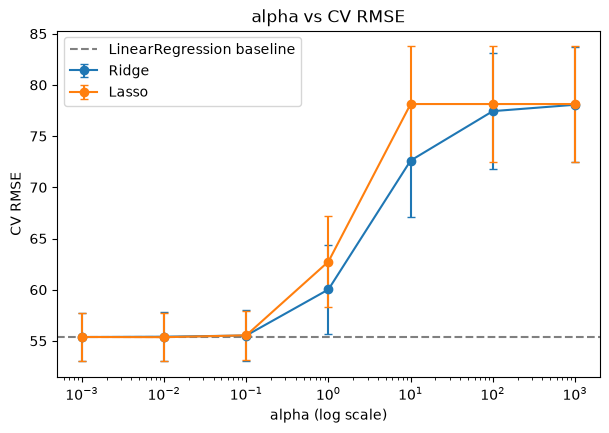

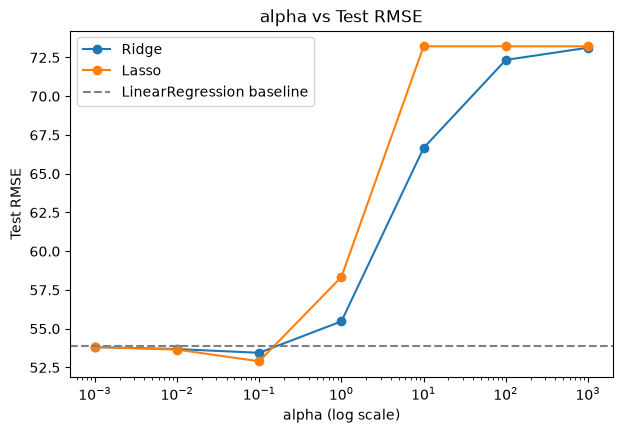

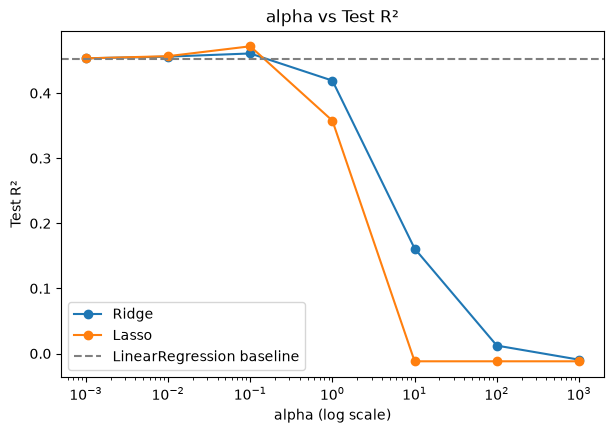

In [24]:
def plot_metric(metric, ylabel, fname, err=None, baseline=None):
    plt.figure(figsize=(7, 4.5))
    for name in ["Ridge", "Lasso"]:
        d = reg_results[reg_results.model == name]
        if err:
            plt.errorbar(d.alpha, d[metric], yerr=d[err], marker="o", capsize=3, label=name)
        else:
            plt.plot(d.alpha, d[metric], marker="o", label=name)
    if baseline is not None:
        plt.axhline(baseline, color="gray", linestyle="--", label="LinearRegression baseline")
    plt.xscale("log")
    plt.xlabel("alpha (log scale)")
    plt.ylabel(ylabel)
    plt.title(f"alpha vs {ylabel}")
    plt.legend()
    plt.savefig(f"D:/Research Project/results/figures/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

plot_metric("cv_RMSE_mean", "CV RMSE", "alpha_vs_cv_rmse.png", err="cv_RMSE_std", baseline=cv_rmse_mean)
plot_metric("test_RMSE", "Test RMSE", "alpha_vs_test_rmse.png", baseline=rmse)
plot_metric("test_R2", "Test R²", "alpha_vs_test_r2.png", baseline=r2)

In [25]:
coef_df = pd.DataFrame(coef_records)

# Table: baseline plus selected alphas
baseline_coefs = pd.Series(lr.coef_, index=X_train.columns, name="OLS")
selected = [0.1, 1, 10, 100]
tbl = {"OLS": baseline_coefs}
for name in ["Ridge", "Lasso"]:
    for a in selected:
        row = coef_df[(coef_df.model == name) & (coef_df.alpha == a)].iloc[0]
        tbl[f"{name} a={a}"] = row[X_train.columns]
coef_compare = pd.DataFrame(tbl).astype(float).round(1)
coef_compare.to_csv("D:/Research Project/results/tables/coef_comparison.csv")
coef_compare

,OLS,Ridge a=0.1,Ridge a=1,Ridge a=10,Ridge a=100,Lasso a=0.1,Lasso a=1,Lasso a=10,Lasso a=100
age,37.9,42.9,45.4,18.2,2.4,0.0,0.0,0.0,0.0
sex,-242.0,-205.5,-76.7,-3.3,0.0,-152.7,-0.0,0.0,0.0
bmi,542.4,505.1,291.3,65.1,7.7,552.7,413.4,0.0,0.0
bp,347.7,317.1,199.0,48.2,5.8,303.4,34.8,0.0,0.0
s1,-931.5,-108.5,-0.5,16.2,2.5,-81.4,0.0,0.0,0.0
s2,518.1,-86.2,-28.6,10.9,1.9,-0.0,0.0,0.0,0.0
s3,163.4,-190.4,-144.5,-39.2,-4.8,-229.3,-0.0,0.0,0.0
s4,275.3,151.7,119.3,41.4,5.4,0.0,0.0,0.0,0.0
s5,736.2,392.3,230.2,58.0,7.1,447.9,258.2,0.0,0.0
s6,48.7,79.9,112.1,39.4,5.0,29.6,0.0,0.0,0.0


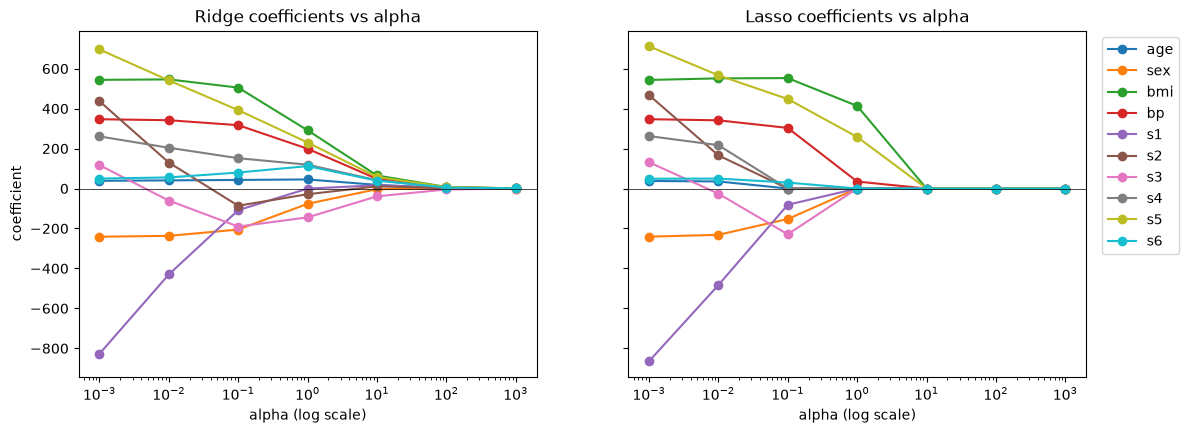

In [26]:
# Coefficient paths
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    d = coef_df[coef_df.model == name].sort_values("alpha")
    for feat in X_train.columns:
        ax.plot(d.alpha, d[feat], marker="o", label=feat)
    ax.set_xscale("log")
    ax.set_xlabel("alpha (log scale)")
    ax.set_title(f"{name} coefficients vs alpha")
    ax.axhline(0, color="black", linewidth=0.5)
axes[0].set_ylabel("coefficient")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig("D:/Research Project/results/figures/coef_paths.png", dpi=150, bbox_inches="tight")
plt.show()

On CV RMSE the best values are Lasso α=0.01 (55.36) and Ridge α=0.001 (55.38), versus the baseline's 55.39. The differences are about 0.02 to 0.03, against a CV std of about 2.4.
On test RMSE, Lasso α=0.1 reaches 52.90 and Ridge α=0.1 reaches 53.45, versus 53.85 (R² 0.472 and 0.461 versus 0.453). That looks like an improvement, but it is under 1 RMSE point on 89 test rows, smaller than the fold-to-fold noise. The CV estimate for the same models (Lasso 55.54, Ridge 55.53) is slightly worse than the baseline, so the CV scores don't back up the test gain.
no meaningful improvement over the baseline


No alpha clearly beats the baseline (differences are inside the CV std of about 2.4).
Ridge shrinks smoothly, while Lasso drops features (3 at α=0.1, 7 at α=1).
The s1/s2 coefficients shrink from -931 and +518 to about -100 without losing accuracy.

# Phase 4 — Experiment 2: Effect of Training-Set Size

In [27]:
from sklearn.model_selection import GridSearchCV, KFold

fractions = [0.10, 0.25, 0.50, 0.75, 1.00]
seeds = list(range(20))
alpha_grid = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

def fit_and_score(name, X_sub, y_sub, X_te, y_te, seed):
    if name == "LinearRegression":
        est = LinearRegression().fit(X_sub, y_sub)
        best_alpha = np.nan
    else:
        base = Ridge() if name == "Ridge" else Lasso(max_iter=100000)
        gs = GridSearchCV(
            base, {"alpha": alpha_grid},
            cv=KFold(n_splits=5, shuffle=True, random_state=seed),
            scoring="neg_root_mean_squared_error",
        )
        gs.fit(X_sub, y_sub)
        est = gs.best_estimator_
        best_alpha = gs.best_params_["alpha"]
    pred = est.predict(X_te)
    return {
        "test_RMSE": np.sqrt(mean_squared_error(y_te, pred)),
        "test_R2": r2_score(y_te, pred),
        "best_alpha": best_alpha,
        "n_zero_coefs": int((est.coef_ == 0).sum()),
    }

def run_experiment(X_tr, y_tr, X_te, y_te, seeds, fractions):
    rows = []
    for seed in seeds:
        order = np.random.RandomState(seed).permutation(len(X_tr))
        for frac in fractions:
            n = int(round(frac * len(X_tr)))
            idx = order[:n]
            X_sub, y_sub = X_tr.iloc[idx], y_tr.iloc[idx]
            for name in ["LinearRegression", "Ridge", "Lasso"]:
                res = fit_and_score(name, X_sub, y_sub, X_te, y_te, seed)
                rows.append({"seed": seed, "fraction": frac, "n_train": n,
                             "model": name, **res})
    return pd.DataFrame(rows)

size_results = run_experiment(X_train, y_train, X_test, y_test, seeds, fractions)
size_results.to_csv("D:/Research Project/results/tables/training_size_raw.csv", index=False)
print(sorted(size_results.n_train.unique()))   # [35, 88, 176, 265, 353]

[np.int64(35), np.int64(88), np.int64(176), np.int64(265), np.int64(353)]


In [28]:
summary = (size_results
    .groupby(["model", "fraction", "n_train"])
    .agg(test_RMSE_mean=("test_RMSE", "mean"), test_RMSE_std=("test_RMSE", "std"),
        test_R2_mean=("test_R2", "mean"), test_R2_std=("test_R2", "std"),
        median_alpha=("best_alpha", "median"),
        mean_zero_coefs=("n_zero_coefs", "mean"))
    .reset_index())
summary.to_csv("D:/Research Project/results/tables/training_size_summary.csv", index=False)
summary.round(3)

,model,fraction,n_train,test_RMSE_mean,test_RMSE_std,test_R2_mean,test_R2_std,median_alpha,mean_zero_coefs
0,Lasso,0.10,35,61.863,6.185,0.271,0.154,0.100,4.10
1,Lasso,0.25,88,55.872,2.154,0.410,0.046,0.100,2.55
2,Lasso,0.50,176,54.763,1.301,0.434,0.027,0.010,1.40
3,Lasso,0.75,265,53.831,0.505,0.453,0.010,0.010,0.70
4,Lasso,1.00,353,53.735,0.085,0.455,0.002,0.006,0.00
5,LinearRegression,0.10,35,65.502,6.567,0.182,0.170,NaN,0.00
6,LinearRegression,0.25,88,57.056,2.190,0.385,0.048,NaN,0.00
7,LinearRegression,0.50,176,55.152,1.206,0.426,0.025,NaN,0.00
8,LinearRegression,0.75,265,54.112,0.490,0.447,0.010,NaN,0.00
9,LinearRegression,1.00,353,53.853,0.000,0.453,0.000,NaN,0.00


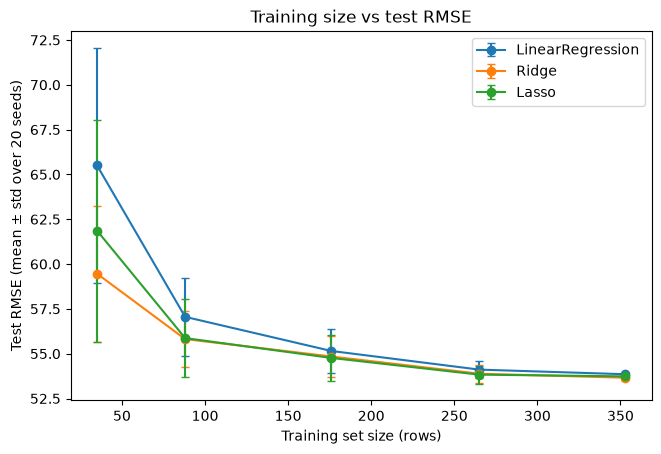

In [29]:
plt.figure(figsize=(7.5, 4.8))
for name in ["LinearRegression", "Ridge", "Lasso"]:
    d = summary[summary.model == name]
    plt.errorbar(d.n_train, d.test_RMSE_mean, yerr=d.test_RMSE_std,
                    marker="o", capsize=3, label=name)
plt.xlabel("Training set size (rows)")
plt.ylabel("Test RMSE (mean ± std over 20 seeds)")
plt.title("Training size vs test RMSE")
plt.legend()
plt.savefig("D:/Research Project/results/figures/size_vs_test_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
pivot = size_results.pivot_table(index=["seed", "fraction", "n_train"],
                                    columns="model", values="test_RMSE").reset_index()
pivot["Ridge_gain"] = pivot["LinearRegression"] - pivot["Ridge"]
pivot["Lasso_gain"] = pivot["LinearRegression"] - pivot["Lasso"]

gain = (pivot.groupby("n_train")[["Ridge_gain", "Lasso_gain"]]
        .agg(["mean", "std"]).round(3))
gain.to_csv("D:/Research Project/results/tables/regularization_gain.csv")
gain

model   Ridge_gain        Lasso_gain       
              mean    std       mean    std
n_train                                    
35           6.040  4.304      3.639  3.352
88           1.240  1.081      1.184  0.982
176          0.309  0.321      0.389  0.470
265          0.229  0.189      0.281  0.383
353          0.195  0.153      0.118  0.085

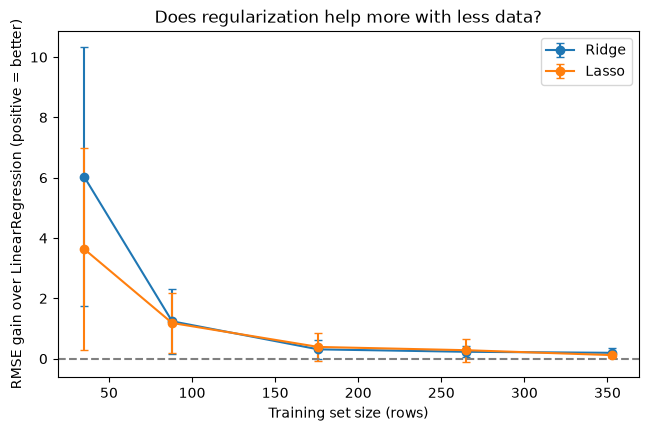

In [31]:
g = pivot.groupby("n_train")[["Ridge_gain", "Lasso_gain"]].agg(["mean", "std"])
plt.figure(figsize=(7.5, 4.5))
for col in ["Ridge_gain", "Lasso_gain"]:
    plt.errorbar(g.index, g[(col, "mean")], yerr=g[(col, "std")],
                 marker="o", capsize=3, label=col.replace("_gain", ""))
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Training set size (rows)")
plt.ylabel("RMSE gain over LinearRegression (positive = better)")
plt.title("Does regularization help more with less data?")
plt.legend()
plt.savefig("D:/Research Project/results/figures/regularization_gain_vs_size.png", dpi=150, bbox_inches="tight")
plt.show()

**Protocol**
- Fixed test set: the same 89 rows from the Phase 2 split (random_state=42); never used for training or alpha selection.
- "100%" = all 353 rows of the training split (not the full 442-row dataset). Other sizes: 35, 88, 176, 265 rows (nested subsets per seed).
- Alpha chosen for Ridge/Lasso by 5-fold shuffled CV on the training subset only (grid 0.001-1000, lowest mean CV RMSE). Same rule at every size.
- 20 random seeds (each changes the subsample and CV folds); results are mean ± std.
- At 100% the training data is identical across seeds, so LinearRegression std = 0 by design.

**Observations**
1. All models improve with more data (LinearRegression test RMSE 65.5 -> 53.85 from 35 to 353 rows).
2. Regularization helps most with little data: RMSE gain over LinearRegression is about 6.0 (Ridge) and 3.6 (Lasso) at 35 rows, about 1.2 at 88 rows, and about 0.1-0.4 from 176 rows up.
3. The gain at 35 rows has a large spread across seeds; from 176 rows up the gain is small relative to seed-to-seed variation.
4. LinearRegression becomes much less stable with small data (RMSE std 6.6 at 35 rows vs 0.49 at 265).
5. Ridge outperforms Lasso at 35 rows (59.5 vs 61.9); they are nearly identical from 88 rows up. Lasso drops ~4 of 10 features on average at 35 rows.
6. Chosen alphas stayed small (Ridge median 0.01 at all sizes; Lasso median 0.1 at 35-88 rows, <=0.01 above).
7. Check: LinearRegression at 100% reproduces the Phase 2 baseline (RMSE 53.853, R² 0.453).

**Conclusion:** regularization is more useful as training data decreases; with 176+ rows its benefit on this dataset is negligible.

**Caveats:** single fixed 89-row test set; seeds resample the same 353-row pool, so subsets overlap heavily at large fractions; at 35 rows each CV validation fold has only 7 samples, so alpha selection is noisy.
An optional check that strengthens point 3

In [32]:
(pivot.assign(Ridge_wins=pivot.Ridge_gain > 0, Lasso_wins=pivot.Lasso_gain > 0).groupby("n_train")[["Ridge_wins", "Lasso_wins"]].mean().round(2))

model,Ridge_wins,Lasso_wins
n_train,,
35,1.00,0.90
88,1.00,0.90
176,0.95,0.95
265,1.00,1.00
353,1.00,1.00


3. Regularization beat LinearRegression in most seeds at every size (win rate: Ridge 0.95-1.00, Lasso 0.90-1.00). At 35-88 rows the gain is large but variable across seeds; from 176 rows up the gain is small (~0.1-0.4 RMSE) but consistently positive. Note: seeds share one fixed test set, and at 353 rows the training data is identical across seeds, so these win rates show stability on this test set, not statistical significance.

In [33]:
import sys; sys.path.append("../src")
from experiment_log import save_experiment_record, audit, lookup, NA

In [34]:
save_experiment_record(
    "exp1_baseline", "EDA and LinearRegression baseline",
    dataset={"name": "sklearn load_diabetes", "n_samples": 442, "n_features": 10},
    preprocessing="None applied (sklearn's features are already mean-centered and scaled)",
    seeds={"train_test_split": 42, "KFold": 42},
    models={"LinearRegression": "default settings"},
    train_test_protocol="80/20 split, random_state=42; test set held out",
    cv_protocol="5-fold shuffled KFold, random_state=42, on the training set only",
    metrics=results,                                  # your Phase 2 results DataFrame
    tables=["baseline_coefficients.csv", "results_table.csv"],
    figures=["target_distribution.png", "correlation_matrix.png", "baseline_actual_vs_predicted.png"],
    observation="CV and test errors agree, so the baseline is stable. Several coefficients (notably the correlated s1/s2 pair) are large and of opposite sign, consistent with multicollinearity.",
)

Saved results/experiments/exp1_baseline.json and .md
WARNING - listed but not found: ['figures/correlation_matrix.png']


{'exp_id': 'exp1_baseline',
 'title': 'EDA and LinearRegression baseline',
 'created': '2026-10-13T01:26:07',
 'dataset': {'name': 'sklearn load_diabetes',
  'n_samples': 442,
  'n_features': 10},
 'preprocessing': "None applied (sklearn's features are already mean-centered and scaled)",
 'seeds': {'train_test_split': 42, 'KFold': 42},
 'models': {'LinearRegression': 'default settings'},
 'train_test_protocol': '80/20 split, random_state=42; test set held out',
 'cv_protocol': '5-fold shuffled KFold, random_state=42, on the training set only',
 'metrics': [{'model': 'LinearRegression',
   'alpha': None,
   'test_MSE': 2900.1936284934804,
   'test_RMSE': 53.85344583676592,
   'test_R2': 0.4526027629719197,
   'cv_RMSE_mean': 55.39463332801855,
   'cv_RMSE_std': 2.3614957385638764}],
 'tables': ['baseline_coefficients.csv', 'results_table.csv'],
 'figures': ['target_distribution.png',
  'correlation_matrix.png',
  'baseline_actual_vs_predicted.png'],
 'observation': 'CV and test errors a

In [35]:
save_experiment_record(
    "exp2_regularization_sweep", "Ridge and Lasso across alpha",
    dataset={"name": "sklearn load_diabetes", "n_samples": 442},
    preprocessing="None applied (same as baseline)",
    seeds={"train_test_split": 42, "KFold": 42},
    models={"Ridge": {"alpha": alphas}, "Lasso": {"alpha": alphas, "max_iter": 100000},
            "LinearRegression": "baseline"},
    train_test_protocol="Same 80/20 split as the baseline; every model evaluated on the same test set",
    cv_protocol="Same 5-fold shuffled KFold (random_state=42) on the training set, same for every model",
    metrics=all_results,
    tables=["regularized_results.csv", "all_results.csv", "coef_comparison.csv"],
    figures=["alpha_vs_cv_rmse.png", "alpha_vs_test_rmse.png", "alpha_vs_test_r2.png", "coef_paths.png"],
    observation="No alpha gave a clear improvement over the baseline. Performance degraded as alpha grew, Ridge shrank coefficients smoothly, and Lasso removed features.",
)

Saved results/experiments/exp2_regularization_sweep.json and .md


{'exp_id': 'exp2_regularization_sweep',
 'title': 'Ridge and Lasso across alpha',
 'created': '2026-10-13T01:26:28',
 'dataset': {'name': 'sklearn load_diabetes', 'n_samples': 442},
 'preprocessing': 'None applied (same as baseline)',
 'seeds': {'train_test_split': 42, 'KFold': 42},
 'models': {'Ridge': {'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
  'Lasso': {'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000], 'max_iter': 100000},
  'LinearRegression': 'baseline'},
 'train_test_protocol': 'Same 80/20 split as the baseline; every model evaluated on the same test set',
 'cv_protocol': 'Same 5-fold shuffled KFold (random_state=42) on the training set, same for every model',
 'metrics': [{'model': 'LinearRegression',
   'alpha': None,
   'cv_RMSE_mean': 55.39463332801855,
   'cv_RMSE_std': 2.3614957385638764,
   'test_RMSE': 53.85344583676592,
   'test_R2': 0.4526027629719197,
   'n_zero_coefs': 0},
  {'model': 'Ridge',
   'alpha': 0.001,
   'cv_RMSE_mean': 55.378370524491594,
   'cv_RMSE_s

In [36]:
save_experiment_record(
    "exp3_training_size", "Regularization vs training-set size",
    dataset={"name": "sklearn load_diabetes", "n_train_pool": len(X_train), "n_test": len(X_test)},
    preprocessing="None applied",
    seeds={"split": 42, "subsampling_and_cv_seeds": list(seeds)},
    models={"LinearRegression": "default", "Ridge": {"alpha_grid": alpha_grid},
            "Lasso": {"alpha_grid": alpha_grid, "max_iter": 100000}},
    train_test_protocol=f"Fixed test set; 100% = all {len(X_train)} training rows; fractions {fractions}; nested random subsets per seed",
    cv_protocol="Alpha chosen per training subset by GridSearchCV, 5-fold shuffled KFold (random_state = seed), lowest mean CV RMSE; test set never used",
    metrics=summary,
    tables=["training_size_raw.csv", "training_size_summary.csv", "regularization_gain.csv"],
    figures=["size_vs_test_rmse.png", "regularization_gain_vs_size.png"],
    observation="Regularization helped most when training data was scarce and its benefit shrank as data grew, while remaining small but consistently positive at larger sizes. Linear regression was least stable at small sizes.",
)

Saved results/experiments/exp3_training_size.json and .md


{'exp_id': 'exp3_training_size',
 'title': 'Regularization vs training-set size',
 'created': '2026-10-13T01:26:39',
 'dataset': {'name': 'sklearn load_diabetes',
  'n_train_pool': 353,
  'n_test': 89},
 'preprocessing': 'None applied',
 'seeds': {'split': 42,
  'subsampling_and_cv_seeds': [0,
   1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19]},
 'models': {'LinearRegression': 'default',
  'Ridge': {'alpha_grid': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
  'Lasso': {'alpha_grid': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
   'max_iter': 100000}},
 'train_test_protocol': 'Fixed test set; 100% = all 353 training rows; fractions [0.1, 0.25, 0.5, 0.75, 1.0]; nested random subsets per seed',
 'cv_protocol': 'Alpha chosen per training subset by GridSearchCV, 5-fold shuffled KFold (random_state = seed), lowest mean CV RMSE; test set never used',
 'metrics': [{'model': 'Lasso',
   'fraction': 0.1,
   'n_train': 35,
   'test_RMSE_